# Object detection in urban scenes (anchor-based, YOLO style)

This notebook trains a small **anchor-based detector** (YOLO style) on synthetic
urban and coastal scenes. The image is split into a `24 x 24` grid; each cell
predicts **6 anchor boxes** of different sizes. We detect six classes —
**building, rock, tree, car, boat, parking** — in a dataset of mostly dense
**urban** blocks with some **urban-fringe** and **coastal (beach)** scenes.

Training uses random **flips** (images and targets together) and keeps the best
checkpoint, which lifts detection mAP. The model runs on Apple **MPS** (or CUDA /
XPU / CPU) in a few minutes.

The next notebook, `09_train_instance_segmentation`, extends this detector with a
mask head per anchor to count trees and separate overlapping crowns in forests.


## Learning objectives

By the end of this notebook you will be able to:

- encode objects as **anchor-based detection targets** (objectness, class, box);
- choose **anchors** with k-means on the training box shapes;
- train a detector with a **multi-task loss** and evaluate it with **mAP@0.5**
  (score threshold, per-class NMS, greedy matching);
- read **precision-recall curves**, mAP at stricter IoU thresholds and the
  **causes of false positives**.

### Exercises

1. Why does mAP@0.5 change when you raise the NMS threshold? Try 0.3 and 0.7.
2. Raise `score_threshold` in `decode_predictions` from 0.05 to 0.3: what
   happens to the number of detections, to precision and recall, and to mAP?
3. Why does the 64 px ablation lose more on the small classes (`car`, `rock`)?

**What to expect.** (1) A higher NMS threshold keeps more overlapping boxes, so
duplicate detections survive and precision (hence mAP) falls; a lower threshold
removes more, risking misses on close objects like parked cars. (2) A higher
`score_threshold` keeps only confident detections: precision rises, recall falls,
and mAP falls too because the precision-recall curve is cut short at low recall.
(3) Going from 96 to 64 px divides every object's pixel area by 2.25, so a
~4 px car shrinks to ~2.7 px and falls below what the grid and the backbone can
localise.


### Key terms

- **anchor** — a prototypical box shape; each `(cell, anchor)` is one prediction
  slot.
- **objectness** — the score that a slot contains an object.
- **NMS** — non-maximum suppression; removes duplicate boxes of the same class:
  boxes are visited by decreasing score and a box is dropped when its IoU with an
  already kept box of the same class exceeds a threshold $\tau$.
- **AP / mAP** — area under the per-class precision-recall curve, and its mean
  over classes, at a given IoU threshold.
- **IoU threshold** — how much overlap counts as a correct detection (0.5 =
  mAP@0.5).


In [1]:
# Google Colab does not preinstall torchinfo (a quiet no-op when it is already present).
%pip install -q torchinfo


Note: you may need to restart the kernel to use updated packages.


In [2]:
# On Google Colab, install mplsyn from GitHub (locally, the editable install is kept).
import sys

if "google.colab" in sys.modules:
    get_ipython().run_line_magic(
        "pip", "install -q git+https://github.com/ogrisel/mplsyn.git")


In [3]:
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import copy
import time

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
np.random.seed(0)

FAST = False  # set True for a quick smoke run (fewer samples / epochs)
def pick_device():
    """Best available device: CUDA, then Apple MPS, then Intel XPU, else CPU."""
    if torch.cuda.is_available():
        return "cuda"
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return "mps"
    if hasattr(torch, "xpu") and torch.xpu.is_available():
        return "xpu"
    return "cpu"


DEVICE = pick_device()
print("torch", torch.__version__, "| device", DEVICE)
if DEVICE == "cpu":
    print("No GPU backend available: training will run on CPU (slower).")


torch 2.15.0 | device mps


## Detection dataset

We focus on six classes that occur in **urban and coastal** scenes:

| class | scene labels |
|---|---|
| building | building, silo |
| rock | rock |
| tree | tree, conifer, bush, orchard |
| car | car, truck, bus |
| boat | boat |
| parking | parking |

Most scenes are dense **urban** blocks (buildings, cars, parking lots, street
trees); **urban-fringe** scenes add low-rise buildings and greenery, and
**coastal** scenes add a sandy beach with boats and shoreline rocks. Each image
is `96 x 96`, the grid is `24 x 24` (stride 4) and we keep at most 24 objects per
image.


In [4]:
from mplsyn.datasets import (
    DETECTION_CLASSES,
    DETECTION_CLASS_INDEX,
    DETECTION_LABEL_MAP,
    DETECTION_MAX_OBJECTS,
    load_detection_data,
)

SIZE = 96
GRID = 24
N_ANCHORS = 6
N_SAMPLES, N_VAL, N_TEST = (180, 40, 32) if FAST else (480, 80, 64)
CLASSES = DETECTION_CLASSES
CLASS_INDEX = DETECTION_CLASS_INDEX
LABEL_MAP = DETECTION_LABEL_MAP
MAX_OBJECTS = DETECTION_MAX_OBJECTS

images, objects_per_image = load_detection_data(N_SAMPLES, SIZE, max_objects=MAX_OBJECTS)
images = torch.from_numpy(images)
print("images", tuple(images.shape))


images (480, 3, 96, 96)


## Anchor boxes (k-means)

Anchor boxes are prototypes of object shapes. Instead of one box per cell we
use **$A=6$ anchors per cell**, giving $S\times S\times A=24\times24\times6=3456$ predictions per
image ($S=24$ is the grid size). We pick the anchors with **scikit-learn's KMeans** (`n_init=10`) on the
`(width, height)` of the training boxes, so the result is stable across runs. This lets different anchors specialise in small, medium or large
(and wide or tall) objects. Because sizes span more than an order of magnitude,
the clustering runs on `(log width, log height)` — clustering raw sizes lets the
few large boxes dominate and starves the small-object anchors.


In [5]:
from mplsyn.datasets import kmeans_anchors, shape_iou

training_boxes = [
    (obj.bbox[2] - obj.bbox[0], obj.bbox[3] - obj.bbox[1])
    for objects in objects_per_image[: N_SAMPLES - N_VAL]
    for obj in objects
]
ANCHORS = kmeans_anchors(training_boxes, N_ANCHORS)
print("boxes:", len(training_boxes))
for anchor_idx, (anchor_w, anchor_h) in enumerate(ANCHORS):
    print(f"anchor {anchor_idx}: width {anchor_w:.3f} height {anchor_h:.3f}")


boxes: 6383
anchor 0: width 0.046 height 0.050
anchor 1: width 0.050 height 0.060
anchor 2: width 0.071 height 0.071
anchor 3: width 0.110 height 0.109
anchor 4: width 0.168 height 0.166
anchor 5: width 0.546 height 0.175


## Encoding targets

Notation used in the rest of the notebook: $S=24$ is the grid size (cells per side, stride 4 px), $A=6$ the number of anchors per cell, $C=6$ the number of classes, $B$ the batch size and $P$ the number of positive slots (ground-truth objects) in a batch. A *slot* is one `(cell, anchor)` pair, so a batch holds $B\,S^2A$ slots.

Boxes are normalised, $(x_0,y_0,x_1,y_1)\in[0,1]^4$, with the $y$ axis pointing **up** (as in the scenes) while grid rows are counted from the **top**, hence the $1-c_y$ below. A ground-truth box has centre $(c_x,c_y)=\big(\tfrac{x_0+x_1}{2},\tfrac{y_0+y_1}{2}\big)$ and size $(w,h)=(x_1-x_0,\;y_1-y_0)$.

For every ground-truth box we choose the anchor $(a_w,a_h)$ with the best **shape IoU**, the IoU of the two boxes once they share the same centre,

$$\mathrm{IoU}_{\text{shape}}=\frac{\min(w,a_w)\,\min(h,a_h)}{w\,h+a_w a_h-\min(w,a_w)\,\min(h,a_h)},$$

and the grid cell that contains its centre,

$$\text{col}=\lfloor c_x S\rfloor,\qquad \text{row}=\lfloor (1-c_y)S\rfloor .$$

That `(cell, anchor)` slot becomes a positive and stores:

- `objectness = 1`;
- the one-hot class;
- box targets `tx, ty, tw, th` with

$$t_x = c_x S - \text{col},\quad t_y = (1-c_y)S - \text{row},\quad
t_w = \log\frac{w}{a_w},\quad t_h = \log\frac{h}{a_h}.$$

$t_x,t_y\in[0,1)$ is the position of the centre inside its cell and $t_w,t_h$ are log-ratios to the anchor size (0 for a box exactly the size of its anchor). The network regresses these four numbers **directly** (raw outputs $\hat t_x,\hat t_y,\hat t_w,\hat t_h$, Smooth-L1 loss, no squashing function). At inference we invert the encoding:

$$b_x = \frac{\text{col}+\hat t_x}{S},\quad
b_y = 1-\frac{\text{row}+\hat t_y}{S},\quad
b_w = a_w e^{\hat t_w},\quad b_h = a_h e^{\hat t_h},$$

and the predicted box is $\big(b_x-\tfrac{b_w}{2},\,b_y-\tfrac{b_h}{2},\,b_x+\tfrac{b_w}{2},\,b_y+\tfrac{b_h}{2}\big)$.


In [6]:
from mplsyn.datasets import encode_targets

objectness, class_target, box_target = [], [], []
for objects in objects_per_image:
    o, c, b = encode_targets(objects, ANCHORS, GRID, CLASSES, CLASS_INDEX, LABEL_MAP)
    objectness.append(o); class_target.append(c); box_target.append(b)
objectness = torch.from_numpy(np.stack(objectness))
class_target = torch.from_numpy(np.stack(class_target))
box_target = torch.from_numpy(np.stack(box_target))

# train / validation (model selection) / test (reported once).
cut = N_VAL + N_TEST
train_images, val_images, test_images = images[:-cut], images[-cut:-N_TEST], images[-N_TEST:]
train_objectness, val_objectness = objectness[:-cut], objectness[-cut:-N_TEST]
train_class, val_class = class_target[:-cut], class_target[-cut:-N_TEST]
train_box, val_box = box_target[:-cut], box_target[-cut:-N_TEST]
train_objects = objects_per_image[:-cut]
val_objects, test_objects = objects_per_image[-cut:-N_TEST], objects_per_image[-N_TEST:]

def _targets(objects_per_image):
    return [[(LABEL_MAP[obj.label], obj.bbox) for obj in objects] for objects in objects_per_image]

ground_truths = _targets(val_objects)
test_ground_truths = _targets(test_objects)
print("train", tuple(train_images.shape), "val", tuple(val_images.shape))
print("positives per train image:", float(objectness[:-N_VAL].sum()) / (N_SAMPLES - N_VAL))


train (336, 3, 96, 96) val (80, 3, 96, 96)
positives per train image: 15.345


## Loss and metric values on toy data (no model yet)

**Losses.** Let $\sigma(z)=1/(1+e^{-z})$, $o_s\in\{0,1\}$ the objectness target of slot $s$ and $z^{o}_s$ its objectness logit, $\mathcal P=\{s: o_s=1\}$ the $P$ positive slots, $N=B\,S^2A$ the total number of slots, $y_{sc}\in\{0,1\}$ the one-hot class target and $z_{sc}$ the class logits, and $t_s,\hat t_s\in\mathbb R^4$ the target and predicted box parameters of slot $s$. The total loss is a weighted sum,

$$\mathcal{L}=\mathcal{L}_{\text{obj}}+2\,\mathcal{L}_{\text{class}}+2\,\mathcal{L}_{\text{box}},$$

with:
- objectness: BCE-with-logits over *all* $N$ slots with a `pos_weight` $w_{+}=5$ to counter the huge number of negatives,
  $$\mathcal{L}_{\text{obj}}=-\frac{1}{N}\sum_{s=1}^{N}\Big[w_{+}\,o_s\log\sigma(z^{o}_s)+(1-o_s)\log\big(1-\sigma(z^{o}_s)\big)\Big];$$
- class: BCE-with-logits only on positive slots (below);
- box: Smooth-L1 only on positive slots, averaged over their $4P$ values,
  $$\mathcal{L}_{\text{box}}=\frac{1}{4P}\sum_{s\in\mathcal P}\sum_{k\in\{x,y,w,h\}}\mathrm{smooth}_{L1}\big(\hat t_{s,k}-t_{s,k}\big),\qquad
  \mathrm{smooth}_{L1}(d)=\begin{cases}\tfrac12 d^2 & |d|<1\\ |d|-\tfrac12 & \text{otherwise.}\end{cases}$$

### Why BCE for a *multi-class* head?

Yes - **BCE = binary cross-entropy**, applied **once per class**, independently.
The class head emits $C$ numbers per slot and the loss treats each as its own
yes/no question:

$$\mathcal{L}_{\text{class}} = -\frac{1}{P\,C}\sum_{s\in\mathcal P}\sum_{c=1}^{C}
\big[y_{sc}\log\sigma(z_{sc}) + (1-y_{sc})\log(1-\sigma(z_{sc}))\big],$$

where $y_s$ is one-hot (exactly one class is 1) and the mean runs over the $P\,C$ values. At inference we take $\hat c=\arg\max_c z_{sc}$, so mutual exclusivity is enforced
*there*, not by a softmax; the detection **score** is $\sigma(z^{o}_s)\cdot\sigma(z_{s\hat c})$ (objectness times class probability).

The alternative is **softmax + categorical cross-entropy**, which couples the
$C$ logits so they compete and sum to 1; that is the textbook choice for
mutually-exclusive single-label classes. We use independent sigmoid + BCE
because it is the standard one-stage-detector convention (YOLO/FCOS): the
classes do not compete, so the same head generalises to **multi-label** targets
and classes can be added or removed without retraining the others.

**Metrics.** For two boxes $a,b$, $\mathrm{IoU}(a,b)=\frac{|a\cap b|}{|a|+|b|-|a\cap b|}$ (areas). A detection is a true positive when its IoU with an unmatched ground-truth box of the same class is $\ge 0.5$; otherwise it is a false positive. For one class, sort the detections by decreasing score; after the first $k$ of them, with $\mathrm{TP}_k,\mathrm{FP}_k$ the cumulative counts and $G$ the number of ground-truth boxes of that class,

$$\mathrm{precision}_k=\frac{\mathrm{TP}_k}{\mathrm{TP}_k+\mathrm{FP}_k},\qquad \mathrm{recall}_k=\frac{\mathrm{TP}_k}{G}.$$

AP is the area under the precision envelope $\tilde p(r)=\max_{r'\ge r}\mathrm{precision}(r')$ (all-point interpolation, recall $r_0=0$),

$$\mathrm{AP}=\sum_k (r_k-r_{k-1})\,\tilde p(r_k),$$

and mAP@0.5 is the mean of the AP over the classes present in the targets (greedy matching, as implemented by `precision_recall_curve` in this notebook).


In [7]:
# Which anchor does a "wide" box pick, and what are its targets?
example_width, example_height = 0.34, 0.16
for anchor_idx, (anchor_w, anchor_h) in enumerate(ANCHORS):
    print(f"anchor {anchor_idx}: shape IoU {shape_iou((example_width, example_height), (anchor_w, anchor_h)):.3f}")
chosen = int(np.argmax([shape_iou((example_width, example_height), a) for a in ANCHORS]))
print("chosen anchor:", chosen)

# Toy objectness logits: one confident positive, two negatives.
example_objectness = torch.tensor([[6.0, -3.0], [-2.0, -4.0]])
example_objectness_target = torch.tensor([[1.0, 0.0], [0.0, 0.0]])
print("objectness BCE:",
      round(float(F.binary_cross_entropy_with_logits(
          example_objectness, example_objectness_target, pos_weight=torch.tensor(5.0))), 3))
manually = -(
    5.0 * example_objectness_target * torch.log(torch.sigmoid(example_objectness))
    + (1 - example_objectness_target) * torch.log(1 - torch.sigmoid(example_objectness))
).mean()
print("manual BCE:    ", round(float(manually), 3), "(same formula, written out)")


anchor 0: shape IoU 0.042
anchor 1: shape IoU 0.055
anchor 2: shape IoU 0.092
anchor 3: shape IoU 0.219
anchor 4: shape IoU 0.484
anchor 5: shape IoU 0.569
chosen anchor: 5
objectness BCE: 0.052
manual BCE:     0.052 (same formula, written out)


### Where do the boxes go? (visual)

The targets are abstract `(cell, anchor)` slots. The figure below makes the
encoding concrete: for a few training images it draws each ground-truth box
(green), the **grid cell** its centre falls in (cyan outline) and the **anchor
index** it matched by shape IoU (labelled `aK`). Each object therefore becomes
exactly one positive slot — the one whose anchor shape is closest to it.

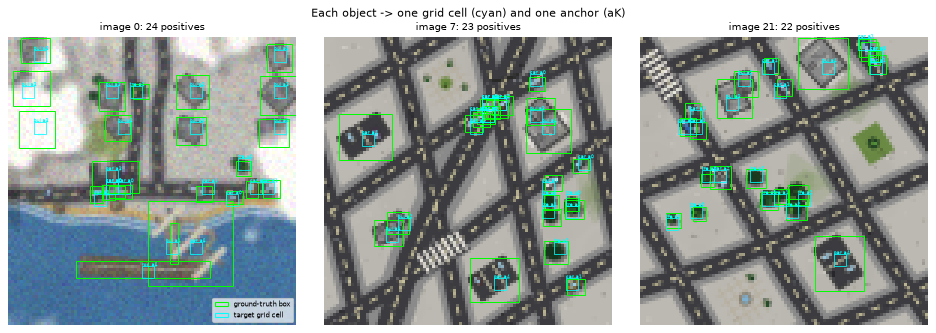

In [8]:
import matplotlib.patches as mpatches
def assigned_slots(objects):
    """Return (class, box, anchor_idx, col, row) for every usable object."""
    slots = []
    for obj in objects:
        x0, y0, x1, y1 = obj.bbox
        width, height = x1 - x0, y1 - y0
        if width <= 0 or height <= 0:
            continue
        anchor_idx = int(np.argmax([shape_iou((width, height), a) for a in ANCHORS]))
        centre_x, centre_y = (x0 + x1) / 2, (y0 + y1) / 2
        col = int(np.clip(centre_x * GRID, 0, GRID - 1))
        row = int(np.clip((1 - centre_y) * GRID, 0, GRID - 1))
        slots.append((LABEL_MAP[obj.label], obj.bbox, anchor_idx, col, row))
    return slots


cell_size = SIZE / GRID
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), dpi=80)
for ax, sample_index in zip(axes, (0, 7, 21)):
    ax.imshow(images[sample_index].permute(1, 2, 0))
    for name, (x0, y0, x1, y1), anchor_idx, col, row in assigned_slots(objects_per_image[sample_index]):
        # ground-truth box
        ax.add_patch(mpatches.Rectangle((x0 * SIZE, (1 - y1) * SIZE), (x1 - x0) * SIZE, (y1 - y0) * SIZE,
                     edgecolor="lime", facecolor="none", linewidth=0.9))
        # target grid cell (row counts from the top)
        ax.add_patch(mpatches.Rectangle((col * cell_size, row * cell_size), cell_size, cell_size,
                     edgecolor="cyan", facecolor="none", linewidth=0.7))
        ax.text(col * cell_size, row * cell_size, f"{name[:3]} a{anchor_idx}", color="cyan", fontsize=4.5)
    ax.set_title(f"image {sample_index}: {len(assigned_slots(objects_per_image[sample_index]))} positives", fontsize=9)
    ax.axis("off")
axes[0].legend(handles=[mpatches.Patch(facecolor="none", edgecolor="lime", label="ground-truth box"),
                        mpatches.Patch(facecolor="none", edgecolor="cyan", label="target grid cell")],
               loc="lower right", fontsize=6, framealpha=0.7)
plt.suptitle("Each object -> one grid cell (cyan) and one anchor (aK)", fontsize=10)
plt.tight_layout()
plt.show()


**Figure read-out.** Each ground-truth box (green), the grid cell its centre falls in (cyan) and the matched anchor index (`aK`). Every object becomes exactly one `(cell, anchor)` slot; dense urban images contain many positives.

In [9]:
def box_iou(box_a, box_b):
    """IoU of two (x0, y0, x1, y1) boxes (bottom-left origin)."""
    left = max(box_a[0], box_b[0]); bottom = max(box_a[1], box_b[1])
    right = min(box_a[2], box_b[2]); top = min(box_a[3], box_b[3])
    intersection = max(0.0, right - left) * max(0.0, top - bottom)
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0


def non_max_suppression(detections, iou_threshold=0.5):
    """Greedily keep the top-scoring boxes, dropping same-class overlaps."""
    # detections: [score, class_idx, x0, y0, x1, y1], highest score first.
    detections = sorted(detections, key=lambda det: -det[0])
    kept = []
    for det in detections:
        suppressed = any(
            other[1] == det[1] and box_iou(other[2:], det[2:]) > iou_threshold
            for other in kept
        )
        if not suppressed:
            kept.append(det)
    return kept


def decode_predictions(predictions, anchors, score_threshold=0.05, top_k=20, iou_threshold=0.5):
    """Turn raw head outputs into per-image [(class, score, box), ...]."""
    objectness = torch.sigmoid(predictions[..., 0])
    class_probs = torch.sigmoid(predictions[..., 5:])
    # tx, ty are regressed raw onto the targets t_x, t_y (see the loss): no sigmoid.
    tx = predictions[..., 1]; ty = predictions[..., 2]
    tw = predictions[..., 3]; th = predictions[..., 4]
    results = []
    for image_idx in range(len(predictions)):
        candidates = []
        for anchor_idx, (anchor_w, anchor_h) in enumerate(anchors):
            for row in range(GRID):
                for col in range(GRID):
                    class_idx = int(class_probs[image_idx, row, col, anchor_idx].argmax())
                    score = float(objectness[image_idx, row, col, anchor_idx]) * float(
                        class_probs[image_idx, row, col, anchor_idx, class_idx])
                    if score < score_threshold:
                        continue
                    center_x = (col + float(tx[image_idx, row, col, anchor_idx])) / GRID
                    center_y = 1 - (row + float(ty[image_idx, row, col, anchor_idx])) / GRID
                    width = anchor_w * float(torch.exp(tw[image_idx, row, col, anchor_idx]))
                    height = anchor_h * float(torch.exp(th[image_idx, row, col, anchor_idx]))
                    candidates.append([
                        score, class_idx,
                        center_x - width / 2, center_y - height / 2,
                        center_x + width / 2, center_y + height / 2,
                    ])
        kept = non_max_suppression(candidates, iou_threshold)[:top_k]
        results.append([(CLASSES[c], s, x0, y0, x1, y1) for s, c, x0, y0, x1, y1 in kept])
    return results


def precision_recall_curve(detections, targets, class_name, iou_threshold=0.5):
    """Return (recall, precision, AP) for one class (greedy matching)."""
    n_positive = sum(1 for boxes in targets for name, _ in boxes if name == class_name)
    if n_positive == 0:
        return None, None, None
    ranked = sorted(
        [(score, image_idx, box)
         for image_idx, dets in enumerate(detections)
         for name, score, *box in dets if name == class_name],
        key=lambda item: -item[0],
    )
    matched = {image_idx: [False] * len(targets[image_idx]) for image_idx in range(len(targets))}
    true_positives, false_positives = [], []
    for _, image_idx, box in ranked:
        best_iou, best_idx = -1.0, -1
        for box_idx, (name, target_box) in enumerate(targets[image_idx]):
            if name == class_name and not matched[image_idx][box_idx]:
                iou = box_iou(box, target_box)
                if iou > best_iou:
                    best_iou, best_idx = iou, box_idx
        if best_iou >= iou_threshold:
            matched[image_idx][best_idx] = True
            true_positives.append(1); false_positives.append(0)
        else:
            true_positives.append(0); false_positives.append(1)
    if not true_positives:
        return np.array([0.0, 1.0]), np.array([0.0, 0.0]), 0.0
    true_positives = np.cumsum(true_positives); false_positives = np.cumsum(false_positives)
    recall = true_positives / n_positive
    precision = true_positives / (true_positives + false_positives)
    recall_curve = np.concatenate([[0], recall, [1]])
    precision_curve = np.concatenate([[0], precision, [0]])
    for k in range(len(precision_curve) - 2, -1, -1):
        precision_curve[k] = max(precision_curve[k], precision_curve[k + 1])
    steps = np.where(recall_curve[1:] != recall_curve[:-1])[0]
    average_precision_value = float(
        ((recall_curve[steps + 1] - recall_curve[steps]) * precision_curve[steps + 1]).sum())
    return recall_curve, precision_curve, average_precision_value


def average_precision(detections, targets, class_name, iou_threshold=0.5):
    """Area under the precision-recall curve for one class (greedy matching)."""
    return precision_recall_curve(detections, targets, class_name, iou_threshold)[2]


def mean_average_precision(detections, targets):
    """Mean AP@0.5 over the classes that appear in the targets."""
    per_class = {name: average_precision(detections, targets, name) for name in CLASSES}
    present = {name: value for name, value in per_class.items() if value is not None}
    return float(np.mean(list(present.values()))), per_class


## Model

A small convolutional backbone (`96 -> 48 -> 24`) followed by a `1 x 1`
head that outputs, for every cell, `A * (5 + C)` values: `1` objectness,
`4` box offsets and `C` class logits (shared weights across locations).


In [10]:
class AnchorDetector(nn.Module):
    """YOLO-style detector: a shared backbone plus one anchor-aware head."""

    def __init__(self, n_anchors, n_classes, base=32):
        super().__init__()

        def block(in_channels, out_channels, stride=1):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
            )

        self.n_anchors = n_anchors
        self.n_classes = n_classes
        # Two stride-2 blocks downsample 96 -> 48 -> 24; the 1x1 head then
        # predicts, for every cell and anchor: 1 objectness + 4 box + C classes.
        self.backbone = nn.Sequential(block(3, base, 2), block(base, base * 2, 2))
        self.head = nn.Conv2d(base * 2, n_anchors * (5 + n_classes), 1)

    def forward(self, image_batch):
        features = self.backbone(image_batch)
        raw = self.head(features)
        # Reshape (B, A, 5+C, S, S) into per-cell predictions (B, S, S, A, 5+C).
        raw = raw.view(len(image_batch), self.n_anchors, 5 + self.n_classes, GRID, GRID)
        return raw.permute(0, 3, 4, 1, 2).contiguous()


model = AnchorDetector(N_ANCHORS, len(CLASSES)).to(DEVICE)
n_parameters = sum(p.numel() for p in model.parameters())
print(f"{n_parameters/1e3:.1f} k parameters")


70.0 k parameters


In [11]:
from torchinfo import summary

# One image through the network (batch size 1): shapes and counts are per sample.
summary(
    model, input_size=(1, 3, SIZE, SIZE), depth=2, mode="eval", device=DEVICE,
    verbose=0, col_names=("input_size", "output_size", "num_params", "mult_adds"),
)


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Mult-Adds
AnchorDetector                           [1, 3, 96, 96]            [1, 24, 24, 6, 11]        --                        --
├─Sequential: 1-1                        [1, 3, 96, 96]            [1, 64, 24, 24]           --                        --
│    └─Sequential: 2-1                   [1, 3, 96, 96]            [1, 32, 48, 48]           10,208                    23,224,448
│    └─Sequential: 2-2                   [1, 32, 48, 48]           [1, 64, 24, 24]           55,552                    31,850,752
├─Conv2d: 1-2                            [1, 64, 24, 24]           [1, 66, 24, 24]           4,290                     2,471,040
Total params: 70,050
Trainable params: 70,050
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 57.55
Input size (MB): 0.11
Forward/backward pass size (MB): 3.84
Params size (MB): 0.28
Estimated Total Size (MB): 4.23

### What `torchinfo` tells us about `AnchorDetector`

Numbers below are per `96 x 96` RGB image (batch size 1).

- **Output shape.** Two stride-2 blocks give `[1, 3, 96, 96] -> [1, 32, 48, 48] -> [1, 64, 24, 24]`. The `1x1` head then produces `[1, 66, 24, 24]`, i.e. 66 = 6 anchors x 11 numbers (1 objectness + 4 box + 6 classes) per cell. The `view` / `permute` in `forward` is not a layer, so `torchinfo` shows the head row with 66 channels and the root row with the reshaped output `[1, 24, 24, 6, 11]`: a `24x24` grid of cells, 6 anchors each, 11 numbers per anchor.
- **Many slots, few objects.** That is 24 x 24 x 6 = 3,456 anchor slots (38,016 numbers) per image, whereas an image holds about 15 ground-truth objects: well under 1 % of the slots are positives. This imbalance is why the objectness loss uses `pos_weight`.
- **Parameters (70,050, about 70 k).** The backbone holds 65,760 of them (94 %) and the head only 4,290 (6 %): detection adds a thin prediction layer on top of a shared feature extractor. This is the smallest network of the modeling notebooks.
- **Compute (about 58 M multiply-adds)** is dominated by the two backbone blocks (23 M and 32 M); the head costs 2.5 M.


## Training loop

We optimise `objectness + 2 * class + 2 * box` with AdamW. Each batch is randomly
flipped (horizontally / vertically, with the target tensor flipped the same way)
and given a per-image brightness / contrast jitter, which acts as strong augmentation so the model no longer overfits after
~30 epochs. Every 10 epochs we decode the validation set and keep the checkpoint
with the best mAP@0.5. The **training and validation loss curves** (plus
validation mAP@0.5) below show both losses falling, then flattening — the peak
of the mAP curve is the checkpoint we keep.

### Training recipe (detection)

| item | value |
|---|---|
| model | anchor detector, 6 anchors/cell on a 24x24 grid (70 k params) |
| input | 96x96 RGB |
| loss | objectness + 2*class + 2*box |
| optimiser | AdamW, lr 1e-3 |
| epochs / batch | 100 / 16 |
| augmentation | horizontal/vertical flips + brightness/contrast jitter |
| data | 336 train / 80 val / 64 test, ~40 % cloud cover |

In [12]:
def flip_batch(images, objectness, class_target, box_target, rng):
    """Random horizontal / vertical flips; flip the targets to match."""
    if rng.random() < 0.5:  # horizontal flip: mirror columns, invert tx
        images = torch.flip(images, [3])
        objectness = torch.flip(objectness, [2]).clone()
        class_target = torch.flip(class_target, [2]).clone()
        box_target = torch.flip(box_target, [2]).clone()
        box_target[..., 0] = 1 - box_target[..., 0]
    if rng.random() < 0.5:  # vertical flip: mirror rows, invert ty
        images = torch.flip(images, [2])
        objectness = torch.flip(objectness, [1]).clone()
        class_target = torch.flip(class_target, [1]).clone()
        box_target = torch.flip(box_target, [1]).clone()
        box_target[..., 1] = 1 - box_target[..., 1]
    # Photometric jitter: per-image brightness / contrast.
    scale = torch.empty(len(images), 1, 1, 1).uniform_(0.8, 1.2)
    shift = torch.empty(len(images), 1, 1, 1).uniform_(-0.06, 0.06)
    images = torch.clamp(images * scale + shift, 0, 1)
    return images, objectness, class_target, box_target


optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
EPOCHS, BATCH_SIZE = (30 if FAST else 100), 16
POS_WEIGHT, CLASS_WEIGHT, BOX_WEIGHT = 5.0, 2.0, 2.0
pos_weight = torch.tensor(POS_WEIGHT, device=DEVICE)
rng = np.random.default_rng(0)

val_images_device = val_images.to(DEVICE)
val_objectness_device = val_objectness.to(DEVICE)
val_class_device = val_class.to(DEVICE)
val_box_device = val_box.to(DEVICE)
best_mean_ap, best_state = 0.0, None
history = []
started = time.time()
for epoch in range(EPOCHS):
    model.train()
    permutation = torch.randperm(len(train_images), device="cpu")
    running_loss = 0.0
    for start in range(0, len(train_images), BATCH_SIZE):
        batch_indices = permutation[start : start + BATCH_SIZE]
        batch_images, batch_objectness, batch_class, batch_box = flip_batch(
            train_images[batch_indices], train_objectness[batch_indices],
            train_class[batch_indices], train_box[batch_indices], rng)
        batch_images = batch_images.to(DEVICE)
        batch_objectness = batch_objectness.to(DEVICE)
        batch_class = batch_class.to(DEVICE)
        batch_box = batch_box.to(DEVICE)
        optimizer.zero_grad()
        # Forward pass: objectness / class / box logits for every cell and anchor.
        predictions = model(batch_images)
        objectness_logit = predictions[..., 0]
        class_logit = predictions[..., 5:]
        box_prediction = predictions[..., 1:5]
        # Only slots that contain an object contribute class / box gradients.
        positive_mask = batch_objectness > 0.5
        objectness_loss = F.binary_cross_entropy_with_logits(
            objectness_logit, batch_objectness, pos_weight=pos_weight)
        class_loss = F.binary_cross_entropy_with_logits(
            class_logit[positive_mask], batch_class[positive_mask])
        box_loss = F.smooth_l1_loss(
            box_prediction[positive_mask], batch_box[positive_mask])
        loss = objectness_loss + CLASS_WEIGHT * class_loss + BOX_WEIGHT * box_loss
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(batch_indices)
    if epoch % 10 == 9 or epoch == EPOCHS - 1:
        model.eval()
        with torch.no_grad():
            predictions = model(val_images_device)
            # Same multi-task loss as training, now on the held-out validation set.
            validation_positive = val_objectness_device > 0.5
            validation_objectness_loss = F.binary_cross_entropy_with_logits(
                predictions[..., 0], val_objectness_device, pos_weight=pos_weight)
            validation_class_loss = F.binary_cross_entropy_with_logits(
                predictions[..., 5:][validation_positive], val_class_device[validation_positive])
            validation_box_loss = F.smooth_l1_loss(
                predictions[..., 1:5][validation_positive], val_box_device[validation_positive])
            validation_loss = (validation_objectness_loss
                               + CLASS_WEIGHT * validation_class_loss
                               + BOX_WEIGHT * validation_box_loss).item()
        detections = decode_predictions(predictions.cpu(), ANCHORS)
        mean_ap, _ = mean_average_precision(detections, ground_truths)
        # Keep the checkpoint with the best validation mAP@0.5.
        if mean_ap > best_mean_ap:
            best_mean_ap = mean_ap
            best_state = copy.deepcopy(model.state_dict())
        history.append((epoch, running_loss / len(train_images), validation_loss, mean_ap))
        print(
            f"epoch {epoch:3d} | loss {running_loss/len(train_images):.3f}"
            f" | val loss {validation_loss:.3f} | mAP@0.5 {mean_ap:.3f}"
            f" | best {best_mean_ap:.3f} | {time.time()-started:.0f}s"
        )
model.load_state_dict(best_state)
print(f"best mAP@0.5 {best_mean_ap:.3f} | training time {time.time()-started:.1f} s")


epoch   9 | loss 0.281 | val loss 0.347 | mAP@0.5 0.100 | best 0.100 | 10s


epoch  19 | loss 0.173 | val loss 0.201 | mAP@0.5 0.221 | best 0.221 | 19s


epoch  29 | loss 0.123 | val loss 0.164 | mAP@0.5 0.296 | best 0.296 | 28s


epoch  39 | loss 0.102 | val loss 0.166 | mAP@0.5 0.351 | best 0.351 | 37s


epoch  49 | loss 0.085 | val loss 0.160 | mAP@0.5 0.444 | best 0.444 | 45s


epoch  59 | loss 0.080 | val loss 0.146 | mAP@0.5 0.465 | best 0.465 | 53s


epoch  69 | loss 0.068 | val loss 0.148 | mAP@0.5 0.496 | best 0.496 | 62s


epoch  79 | loss 0.066 | val loss 0.181 | mAP@0.5 0.492 | best 0.496 | 69s


epoch  89 | loss 0.063 | val loss 0.160 | mAP@0.5 0.499 | best 0.499 | 77s


epoch  99 | loss 0.060 | val loss 0.142 | mAP@0.5 0.525 | best 0.525 | 85s
best mAP@0.5 0.525 | training time 84.9 s


## Data augmentation, visualised

The training loop augments every batch with random **flips** (horizontal /
vertical) and a **brightness / contrast jitter**. A flip is label-preserving
because mirroring the image mirrors each box with it; the photometric jitter
changes only brightness, so the geometry is untouched. The grid below shows
one training image under each transform, with the boxes transformed the same
way — the targets remain valid.

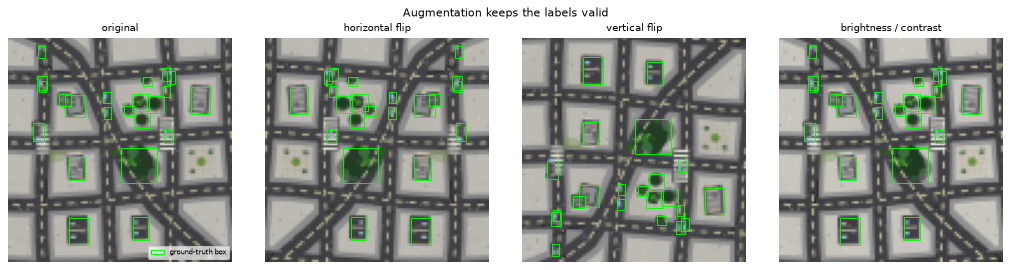

In [13]:
import matplotlib.patches as mpatches


def draw_scene_boxes(ax, boxes, color="lime"):
    """Draw (class, (x0, y0, x1, y1)) boxes in bottom-left scene coords."""
    for _name, (x0, y0, x1, y1) in boxes:
        ax.add_patch(mpatches.Rectangle(
            (x0 * SIZE, (1 - y1) * SIZE), (x1 - x0) * SIZE, (y1 - y0) * SIZE,
            edgecolor=color, facecolor="none", linewidth=0.8))


def horizontal_flip(image, boxes):
    """Mirror left-right; mirror every box the same way (x -> 1 - x)."""
    return torch.flip(image, [2]), [(n, (1 - x1, y0, 1 - x0, y1)) for n, (x0, y0, x1, y1) in boxes]


def vertical_flip(image, boxes):
    """Mirror top-bottom; mirror every box the same way (y -> 1 - y)."""
    return torch.flip(image, [1]), [(n, (x0, 1 - y1, x1, 1 - y0)) for n, (x0, y0, x1, y1) in boxes]


def brightness_contrast(image, seed=0):
    """The photometric jitter from the training loop (geometry unchanged)."""
    generator = torch.Generator().manual_seed(seed)
    scale = torch.empty(1, 1, 1).uniform_(0.8, 1.2, generator=generator)
    shift = torch.empty(1, 1, 1).uniform_(-0.06, 0.06, generator=generator)
    return torch.clamp(image * scale + shift, 0, 1)


sample_index = 2
sample_image = images[sample_index]
sample_boxes = [(LABEL_MAP[obj.label], obj.bbox) for obj in objects_per_image[sample_index]]
variants = [
    ("original", sample_image, sample_boxes),
    ("horizontal flip", *horizontal_flip(sample_image, sample_boxes)),
    ("vertical flip", *vertical_flip(sample_image, sample_boxes)),
    ("brightness / contrast", brightness_contrast(sample_image, seed=1), sample_boxes),
]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), dpi=80)
for ax, (title, image, boxes) in zip(axes, variants):
    ax.imshow(image.permute(1, 2, 0))
    draw_scene_boxes(ax, boxes)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
axes[0].legend(handles=[mpatches.Patch(facecolor="none", edgecolor="lime", label="ground-truth box")],
               loc="lower right", fontsize=6, framealpha=0.7)
plt.suptitle("Augmentation keeps the labels valid", fontsize=10)
plt.tight_layout()
plt.show()


**Figure read-out.** One training image under horizontal flip, vertical flip and brightness/contrast, with the boxes transformed identically - the labels stay valid.

## Detection evaluation

Final mAP@0.5 per class (evaluated with the best checkpoint), the **training
curves** (loss and validation mAP@0.5 vs epoch) and a few validation images with
ground truth (green) and predictions (red). We also print the **no-object
baseline** (mAP 0): the metric is only meaningful between that floor and a
perfect oracle (mAP 1). **Per-class precision-recall curves** show what the
single mAP number averages.


/var/folders/93/0_k_9bh97fj_15hzk2bhy5r00000gn/T/ipykernel_43981/724735886.py:41: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  score = float(objectness[image_idx, row, col, anchor_idx]) * float(


validation mAP@0.5 = 0.525
test       mAP@0.5 = 0.566   <- reported once, never used for tuning
per-class AP@0.5:
  building    0.729
  rock        0.316
  tree        0.575
  car         0.305
  boat        0.766
  parking     0.460
no-object baseline      mAP@0.5 = 0.000


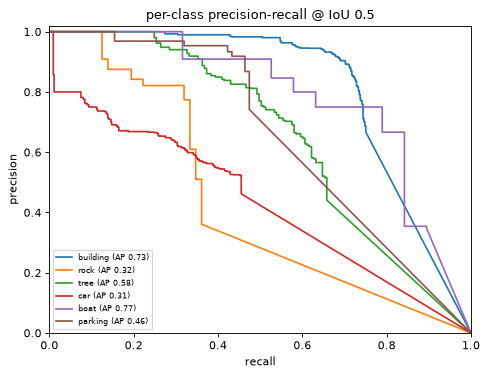

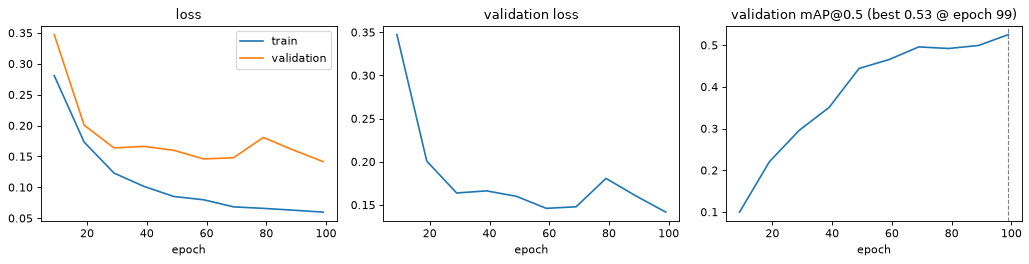

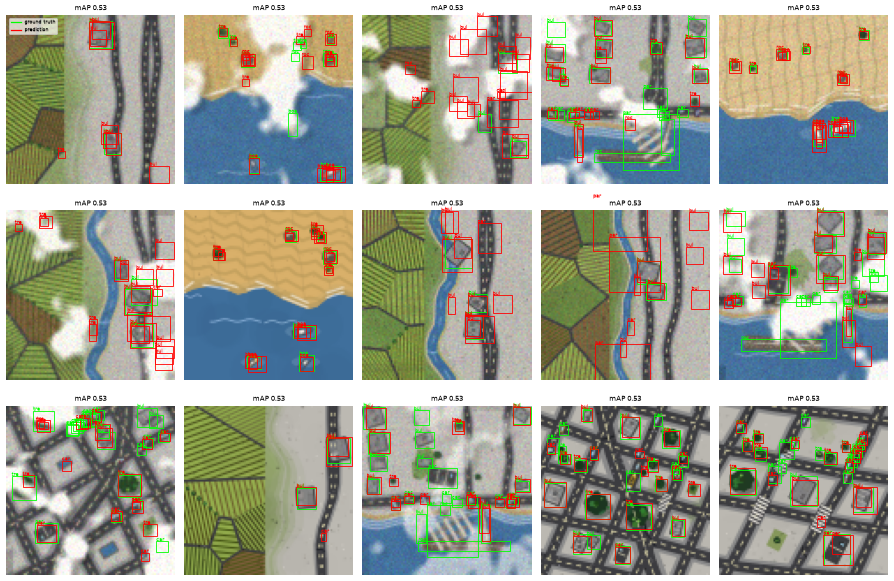

In [14]:
model.eval()
with torch.no_grad():
    predictions = model(val_images_device).cpu()
detections = decode_predictions(predictions, ANCHORS)
mean_ap, per_class_ap = mean_average_precision(detections, ground_truths)
test_predictions = model(test_images.to(DEVICE)).cpu()   # held-out test set
test_detections = decode_predictions(test_predictions, ANCHORS)
test_mean_ap, _ = mean_average_precision(test_detections, test_ground_truths)
print(f"validation mAP@0.5 = {mean_ap:.3f}")
print(f"test       mAP@0.5 = {test_mean_ap:.3f}   <- reported once, never used for tuning")
print("per-class AP@0.5:")
for class_name in CLASSES:
    value = per_class_ap[class_name]
    print(f"  {class_name:11s} {'-' if value is None else f'{value:.3f}'}")

# Reference points for mAP@0.5: an empty prediction set scores 0 (lower bound),
# a perfect oracle 1. Every point between is earned by the detector.
print("no-object baseline      mAP@0.5 = 0.000")

# Per-class precision-recall curves: AP is the area under each curve and
# mAP@0.5 is their mean over the classes present, so a rare class's noisy AP
# counts as much as a common one.
fig, ax = plt.subplots(figsize=(6.2, 4.8), dpi=80)
for class_name in CLASSES:
    recall_curve, precision_curve, ap = precision_recall_curve(detections, ground_truths, class_name)
    if recall_curve is None:
        continue
    ax.plot(recall_curve, precision_curve, label=f"{class_name} (AP {ap:.2f})")
ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_title("per-class precision-recall @ IoU 0.5")
ax.legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()

# Training curves: the training loss falls while validation mAP@0.5 rises,
# then both flatten. The best checkpoint is the peak of the mAP curve.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), dpi=80)
epochs = [row[0] for row in history]
axes[0].plot(epochs, [row[1] for row in history], label="train")
axes[0].plot(epochs, [row[2] for row in history], label="validation")
axes[0].set_title("loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(epochs, [row[2] for row in history])
axes[1].set_title("validation loss"); axes[1].set_xlabel("epoch")
best_epoch = epochs[int(np.argmax([row[3] for row in history]))]
axes[2].plot(epochs, [row[3] for row in history])
axes[2].axvline(best_epoch, color="grey", linestyle="--", linewidth=1)
axes[2].set_title(f"validation mAP@0.5 (best {max(row[3] for row in history):.2f} @ epoch {best_epoch})")
axes[2].set_xlabel("epoch")
plt.tight_layout()
plt.show()


def draw_boxes(ax, boxes, color):
    """Draw (class, score, x0, y0, x1, y1) boxes on a scene axis."""
    for class_name, score, x0, y0, x1, y1 in boxes:
        ax.add_patch(plt.Rectangle(
            (x0 * SIZE, (1 - y1) * SIZE), (x1 - x0) * SIZE, (y1 - y0) * SIZE,
            edgecolor=color, facecolor="none", linewidth=1.0))
        ax.text(x0 * SIZE, (1 - y1) * SIZE, class_name[:3], color=color, fontsize=6)


# Qualitative check: three rows of five validation scenes, ground truth (green)
# against the best-checkpoint predictions (red).
fig, axes = plt.subplots(3, 5, figsize=(15, 10), dpi=60)
for sample_idx, ax in enumerate(axes.ravel()):
    ax.imshow(val_images[sample_idx].permute(1, 2, 0))
    draw_boxes(ax, [(n, 1.0, *b) for n, b in ground_truths[sample_idx]], "lime")
    draw_boxes(ax, detections[sample_idx], "red")
    ax.set_title(f"mAP {mean_ap:.2f}", fontsize=8)
    ax.axis("off")
legend_handles = [plt.Line2D([], [], color="lime", label="ground truth"),
                  plt.Line2D([], [], color="red", label="prediction")]
axes.ravel()[0].legend(handles=legend_handles, loc="upper left", fontsize=6, framealpha=0.7)
plt.tight_layout()
plt.show()


**Figure read-out.** Per-class precision-recall curves (AP per class), then train/validation loss and validation mAP, then validation scenes with ground truth (green) and predictions (red). Test mAP@0.5 is about 0.57 (validation 0.53). The weakest classes are `car` and `rock` (AP about 0.3), then `parking` (about 0.46): small objects, and objects under opaque cloud, are hard or unrecoverable. `boat`, `building` and `tree` are the best.

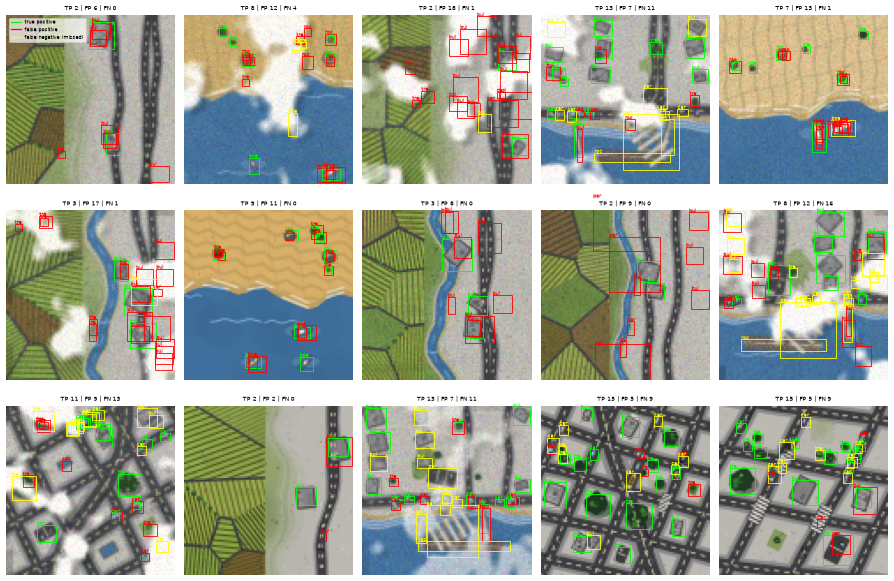

In [15]:
def match_detections(detections, targets, iou_threshold=0.5):
    """Greedy per-image matching; return (true positives, false positives, misses)."""
    true_positives, false_positives, false_negatives = [], [], []
    for image_idx in range(len(detections)):
        matched = [False] * len(targets[image_idx])
        image_tp, image_fp = [], []
        for detection in sorted(detections[image_idx], key=lambda det: -det[1]):
            class_name, score, *box = detection
            best_iou, best_idx = -1.0, -1
            for box_idx, (target_name, target_box) in enumerate(targets[image_idx]):
                if target_name == class_name and not matched[box_idx]:
                    iou = box_iou(box, target_box)
                    if iou > best_iou:
                        best_iou, best_idx = iou, box_idx
            if best_iou >= iou_threshold:
                matched[best_idx] = True
                image_tp.append(detection)
            else:
                image_fp.append(detection)
        image_fn = [targets[image_idx][i] for i in range(len(matched)) if not matched[i]]
        true_positives.append(image_tp)
        false_positives.append(image_fp)
        false_negatives.append(image_fn)
    return true_positives, false_positives, false_negatives


true_positives, false_positives, false_negatives = match_detections(detections, ground_truths)

# Failure gallery: matched detections (green), false positives (red) and missed
# ground-truth objects (yellow) over fifteen validation scenes.
fig, axes = plt.subplots(3, 5, figsize=(15, 10), dpi=60)
for sample_idx, ax in enumerate(axes.ravel()):
    ax.imshow(val_images[sample_idx].permute(1, 2, 0))
    draw_boxes(ax, true_positives[sample_idx], "lime")
    draw_boxes(ax, false_positives[sample_idx], "red")
    draw_boxes(ax, [(name, 1.0, *box) for name, box in false_negatives[sample_idx]], "yellow")
    ax.set_title(
        f"TP {len(true_positives[sample_idx])} | FP {len(false_positives[sample_idx])}"
        f" | FN {len(false_negatives[sample_idx])}",
        fontsize=7,
    )
    ax.axis("off")
legend_handles = [plt.Line2D([], [], color="lime", label="true positive"),
                  plt.Line2D([], [], color="red", label="false positive"),
                  plt.Line2D([], [], color="yellow", label="false negative (missed)")]
axes.ravel()[0].legend(handles=legend_handles, loc="upper left", fontsize=6, framealpha=0.7)
plt.tight_layout()
plt.show()


**Figure read-out.** Failure gallery: true positives (green), false positives (red) and missed objects (yellow). Errors cluster on dense cars/trees and partly clouded scenes.

false positives by cause: {'duplicate': 64, 'classification': 6, 'localisation': 323, 'background': 315}
total FP 708, misses (FN) 569


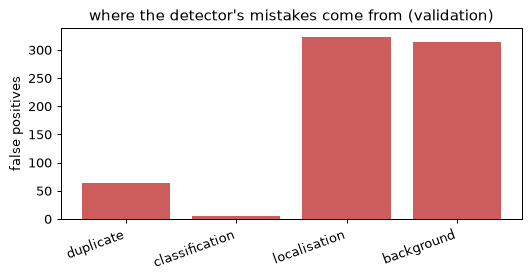

In [16]:
def detection_error_types(detections_split, targets_split, iou_threshold=0.5):
    """Break the false positives into their causes.

    - **duplicate**: a second box on a same-class object already detected;
    - **classification**: overlaps a ground-truth box of another class;
    - **localisation**: overlaps an object but not enough (IoU < threshold);
    - **background**: no object nearby (IoU < 0.1).
    """
    counts = {"duplicate": 0, "classification": 0, "localisation": 0, "background": 0}
    for image_idx in range(len(detections_split)):
        matched = [False] * len(targets_split[image_idx])
        # Greedy matching by score, as in the mAP computation.
        for class_name, score, *box in sorted(detections_split[image_idx], key=lambda d: -d[1]):
            best_iou, best_idx = -1.0, -1
            for box_idx, (target_name, target_box) in enumerate(targets_split[image_idx]):
                if target_name == class_name and not matched[box_idx]:
                    iou = box_iou(box, target_box)
                    if iou > best_iou:
                        best_iou, best_idx = iou, box_idx
            if best_iou >= iou_threshold:
                matched[best_idx] = True
                continue
            same_class_iou = max(
                [box_iou(box, t) for n, t in targets_split[image_idx] if n == class_name],
                default=0.0)
            any_class_iou = max(
                [box_iou(box, t) for n, t in targets_split[image_idx]], default=0.0)
            if same_class_iou >= iou_threshold:
                counts["duplicate"] += 1
            elif any_class_iou >= iou_threshold:
                counts["classification"] += 1
            elif any_class_iou >= 0.1:
                counts["localisation"] += 1
            else:
                counts["background"] += 1
    return counts


error_types = detection_error_types(detections, ground_truths)
total_fp = sum(error_types.values())
print("false positives by cause:", error_types)
print(f"total FP {total_fp}, misses (FN) {sum(len(misses) for misses in false_negatives)}")
fig, ax = plt.subplots(figsize=(6, 3.2), dpi=90)
ax.bar(list(error_types), list(error_types.values()), color="indianred")
ax.set_ylabel("false positives")
ax.set_title("where the detector's mistakes come from (validation)")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.show()


**Figure read-out.** The false positives split by cause: **localisation** (323; the box overlaps an object but not enough for IoU 0.5) and **background** (315; spurious detections in clutter or under cloud) are about equally frequent, then **duplicates** (64); cross-class confusion is negligible (6). Each cause needs a different fix - a finer grid / better box regression for localisation, more data or augmentation for background, NMS tuning for duplicates.

### How the detection metric behaves

**mAP@0.5 vs higher IoU.** A detection counts as correct at IoU >= 0.5, which
is lenient: a box can be off by half its size and still pass. Re-scoring at
IoU 0.65 and 0.75 measures how *tight* the boxes are, and the gap is the
localisation error the headline number hides.

**Score threshold.** `decode_predictions` uses a deliberately permissive score
threshold, so lowering or raising it trades precision against recall and the
number of reported objects. This is the detector's **operating point**.

mAP@0.50 = 0.525
mAP@0.65 = 0.366
mAP@0.75 = 0.175


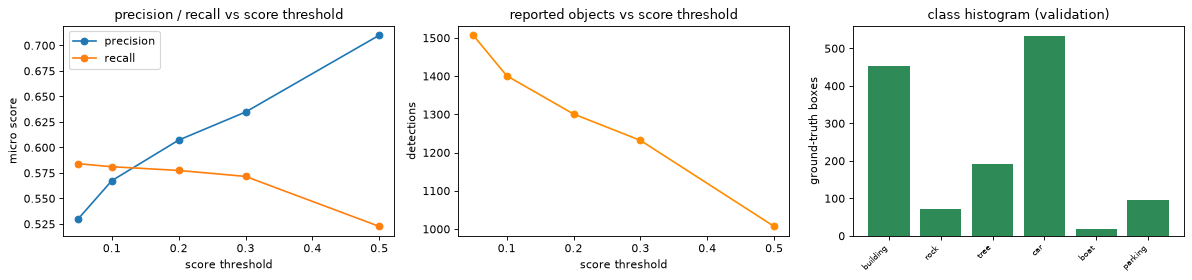

In [17]:
# mAP at stricter IoU thresholds: @0.5 flatters loose boxes.
for iou_threshold in (0.5, 0.65, 0.75):
    aps = [average_precision(detections, ground_truths, name, iou_threshold=iou_threshold)
           for name in CLASSES]
    present = [value for value in aps if value is not None]
    print(f"mAP@{iou_threshold:.2f} = {np.mean(present):.3f}")


def operating_point(detections_split):
    """Micro precision / recall / object count at one operating point."""
    tp = fp = fn = 0
    for image_idx in range(len(detections_split)):
        image_tp, image_fp, image_fn = match_detections(
            [detections_split[image_idx]], [ground_truths[image_idx]])
        tp += len(image_tp[0]); fp += len(image_fp[0]); fn += len(image_fn[0])
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return precision, recall, tp + fp


# Score-threshold sweep: precision, recall and the number of detections.
score_thresholds = [0.05, 0.1, 0.2, 0.3, 0.5]
sweep_precision, sweep_recall, sweep_count = [], [], []
for score_threshold in score_thresholds:
    sweep_detections = decode_predictions(predictions, ANCHORS, score_threshold=score_threshold)
    precision, recall, count = operating_point(sweep_detections)
    sweep_precision.append(precision); sweep_recall.append(recall); sweep_count.append(count)
# Per-class ground-truth counts: a class histogram beside the metrics makes
# AP asymmetries readable (a rare class has a noisy AP and few boxes to learn
# from, a small class like `car` is hard despite being frequent).
ground_truth_counts = np.zeros(len(CLASSES), dtype=int)
for boxes in ground_truths:
    for name, _box in boxes:
        ground_truth_counts[CLASS_INDEX[name]] += 1

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), dpi=80)
axes[0].plot(score_thresholds, sweep_precision, marker="o", label="precision")
axes[0].plot(score_thresholds, sweep_recall, marker="o", label="recall")
axes[0].set_xlabel("score threshold"); axes[0].set_ylabel("micro score")
axes[0].set_title("precision / recall vs score threshold"); axes[0].legend()
axes[1].plot(score_thresholds, sweep_count, marker="o", color="darkorange")
axes[1].set_xlabel("score threshold"); axes[1].set_ylabel("detections")
axes[1].set_title("reported objects vs score threshold")
axes[2].bar(CLASSES, ground_truth_counts, color="seagreen")
axes[2].set_ylabel("ground-truth boxes")
axes[2].set_title("class histogram (validation)")
plt.setp(axes[2].get_xticklabels(), rotation=45, ha="right", fontsize=7)
plt.tight_layout()
plt.show()


**Figure read-out.** mAP at IoU 0.5 / 0.65 / 0.75 and the score-threshold sweep: @0.5 flatters loose boxes, and the threshold trades precision against recall and the reported count. The third panel is the per-class ground-truth histogram, to read which APs rest on few examples.

### Evaluation protocol

Three disjoint splits: **train** (fit), **validation** (checkpoint selection) and
**test** (reported once, never used for any decision). The detection
metrics below are printed for validation and test; the failure
gallery uses validation only, to keep the test set untouched.


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Mult-Adds
AnchorDetector                           [1, 3, 64, 64]            [1, 16, 16, 6, 11]        --                        --
├─Sequential: 1-1                        [1, 3, 64, 64]            [1, 64, 16, 16]           --                        --
│    └─Sequential: 2-1                   [1, 3, 64, 64]            [1, 32, 32, 32]           10,208                    10,322,048
│    └─Sequential: 2-2                   [1, 32, 32, 32]           [1, 64, 16, 16]           55,552                    14,156,032
├─Conv2d: 1-2                            [1, 64, 16, 16]           [1, 66, 16, 16]           4,290                     1,098,240
Total params: 70,050
Trainable params: 70,050
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 25.58
Input size (MB): 0.05
Forward/backward pass size (MB): 1.71
Params size (MB): 0.28
Estimated Total Size (MB): 2.04


resolution ablation | 96 px val 0.525 / test 0.566 || 64 px val 0.184 / test 0.201


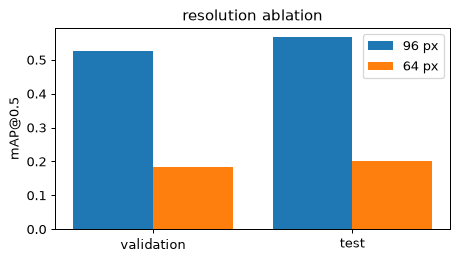

In [18]:
# --- Resolution ablation: 96 px vs 64 px ------------------------------------
# The detection section runs at 96 px. Here we retrain the *same* architecture
# on 64 px scenes (a 16x16 grid) for a short schedule and compare mAP, to
# demonstrate the resolution ceiling discussed in "Interpreting these numbers".
SIZE_HI, GRID_HI, ANCHORS_HI = SIZE, GRID, ANCHORS
SIZE, GRID = 64, 16
try:
    N_LOW, N_VAL_LOW, N_TEST_LOW = 200, 48, 40
    low_images_array, low_objects = load_detection_data(N_LOW, size=SIZE, seed=7)
    low_images = torch.from_numpy(low_images_array)
    low_boxes = [(o.bbox[2] - o.bbox[0], o.bbox[3] - o.bbox[1])
                 for objs in low_objects[: N_LOW - N_VAL_LOW] for o in objs]
    ANCHORS = kmeans_anchors(low_boxes, N_ANCHORS)

    low_objectness, low_class, low_box = [], [], []
    for objs in low_objects:
        o, c, b = encode_targets(objs, ANCHORS, GRID, CLASSES, CLASS_INDEX, LABEL_MAP)
        low_objectness.append(o); low_class.append(c); low_box.append(b)
    low_objectness = torch.from_numpy(np.stack(low_objectness))
    low_class = torch.from_numpy(np.stack(low_class))
    low_box = torch.from_numpy(np.stack(low_box))

    cut_low = N_VAL_LOW + N_TEST_LOW
    low_train_images = low_images[:-cut_low]
    low_val_images = low_images[-cut_low:-N_TEST_LOW].to(DEVICE)
    low_test_images = low_images[-N_TEST_LOW:].to(DEVICE)
    low_train_obj, low_train_cls, low_train_box = (
        low_objectness[:-cut_low], low_class[:-cut_low], low_box[:-cut_low])
    low_val_obj = low_objectness[-cut_low:-N_TEST_LOW].to(DEVICE)
    low_val_cls = low_class[-cut_low:-N_TEST_LOW].to(DEVICE)
    low_val_box = low_box[-cut_low:-N_TEST_LOW].to(DEVICE)
    low_val_gt = _targets(low_objects[-cut_low:-N_TEST_LOW])
    low_test_gt = _targets(low_objects[-N_TEST_LOW:])

    low_model = AnchorDetector(N_ANCHORS, len(CLASSES)).to(DEVICE)
    print(summary(low_model, input_size=(1, 3, SIZE, SIZE), depth=2, mode="eval",
                  device=DEVICE, verbose=0, col_names=("input_size", "output_size", "num_params", "mult_adds")))
    low_optimizer = torch.optim.AdamW(low_model.parameters(), lr=1e-3)
    low_rng = np.random.default_rng(1)
    low_best, low_best_state = 0.0, None
    for epoch in range(40):
        low_model.train()
        permutation = torch.randperm(len(low_train_images))
        for start in range(0, len(low_train_images), BATCH_SIZE):
            idx = permutation[start:start + BATCH_SIZE]
            batch_images, batch_obj, batch_cls, batch_box = flip_batch(
                low_train_images[idx], low_train_obj[idx], low_train_cls[idx],
                low_train_box[idx], low_rng)
            batch_images = batch_images.to(DEVICE); batch_obj = batch_obj.to(DEVICE)
            batch_cls = batch_cls.to(DEVICE); batch_box = batch_box.to(DEVICE)
            low_optimizer.zero_grad()
            low_predictions = low_model(batch_images)
            positive = batch_obj > 0.5
            loss = (F.binary_cross_entropy_with_logits(
                        low_predictions[..., 0], batch_obj, pos_weight=pos_weight)
                    + CLASS_WEIGHT * F.binary_cross_entropy_with_logits(
                        low_predictions[..., 5:][positive], batch_cls[positive])
                    + BOX_WEIGHT * F.smooth_l1_loss(
                        low_predictions[..., 1:5][positive], batch_box[positive]))
            loss.backward(); low_optimizer.step()
        if epoch % 5 == 4 or epoch == 39:
            low_model.eval()
            with torch.no_grad():
                val_detections = decode_predictions(low_model(low_val_images).cpu(), ANCHORS)
            low_map, _ = mean_average_precision(val_detections, low_val_gt)
            if low_map > low_best:
                low_best, low_best_state = low_map, copy.deepcopy(low_model.state_dict())
    low_model.load_state_dict(low_best_state)
    with torch.no_grad():
        test_detections = decode_predictions(low_model(low_test_images).cpu(), ANCHORS)
    low_test_map, _ = mean_average_precision(test_detections, low_test_gt)
    print(f"resolution ablation | 96 px val {mean_ap:.3f} / test {test_mean_ap:.3f}"
          f" || 64 px val {low_best:.3f} / test {low_test_map:.3f}")

    fig, ax = plt.subplots(figsize=(5.2, 3.0), dpi=90)
    positions = np.arange(2)
    ax.bar(positions - 0.2, [mean_ap, test_mean_ap], width=0.4, label="96 px")
    ax.bar(positions + 0.2, [low_best, low_test_map], width=0.4, label="64 px")
    ax.set_xticks(positions, ["validation", "test"]); ax.set_ylabel("mAP@0.5")
    ax.set_title("resolution ablation"); ax.legend()
    plt.tight_layout()
    plt.show()
finally:
    SIZE, GRID, ANCHORS = SIZE_HI, GRID_HI, ANCHORS_HI


**Figure read-out.** mAP@0.5 at 96 px (the main model) vs a short 64 px run of the same architecture. Going from 96 to 64 px divides each object's pixel area by 2.25 (a ~4 px car becomes ~2.7 px), so the small classes collapse and the overall mAP drops: resolution, not capacity, is the binding constraint here.

**Model summary read-out (64 px run).** The summary printed at the top of the cell output shows the very same `AnchorDetector` at `[1, 3, 64, 64]`: **70,050 parameters, exactly as at 96 px**, because convolutions share their weights across positions, so the parameter count does not depend on the image size. The output becomes `[1, 16, 16, 6, 11]`, i.e. 1,536 anchor slots instead of 3,456, and the cost drops from 58 M to 26 M multiply-adds. Both ratios are 2.25 = (96 / 64)^2. The ablation therefore changes the grid and the pixel budget per object, not the model capacity, which supports the conclusion above that resolution is the binding constraint.


### Interpreting these numbers

Detection runs at **96x96** with light sensor noise and ~40 % cloud cover
(mostly opaque, about a quarter semi-transparent); many **cars span only ~4 px**,
so a perfect detection score is physically out of reach.

So the right reading is not "the model is bad" but "these metrics quantify
robustness under realistic conditions":

- High scores on clean renders can mislead; a model that never sees noise or
  clouds can look near-perfect and fail on the first degraded acquisition.
- Clouds, haze, blur and a few pixels per object set a **ceiling** that no
  architecture can beat.
- Some errors are **irreducible** (a ~4 px car, an object under an opaque cloud).
- Evaluation is about an **operating point** (score threshold trades recall for
  precision), not a single number; improving the score means better resolution
  or sensors, not just a bigger network.

**Next.** `09_train_instance_segmentation` reuses this anchor encoding and adds a
mask head per anchor, to count and separate overlapping trees in forests.
